# Exploratory Data Analysis — UIT-VSFC

## Giới thiệu

UIT-VSFC (Vietnamese Students’ Feedback Corpus) là bộ dữ liệu gồm các câu phản hồi tiếng Việt của sinh viên. Mỗi câu có nhãn cảm xúc và nhãn chủ đề, nên dữ liệu có thể được khảo sát cho hai bài toán phân loại văn bản riêng biệt: **phân loại cảm xúc** và **phân loại chủ đề**.

Notebook này khám phá cấu trúc và chất lượng dữ liệu, độ dài câu, phân bố hai loại nhãn và mối liên hệ giữa chủ đề với cảm xúc. Kết quả EDA giúp nhận diện mất cân bằng lớp, vấn đề dữ liệu và những điểm cần lưu ý trước khi xây dựng mô hình.

Các tập `train`, `validation` và `test` được giữ theo cách chia sẵn của bộ dữ liệu. Tỷ lệ nhãn trong dữ liệu chỉ mô tả tập này, không đại diện cho mọi phản hồi sinh viên.

Data Loading

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/raw")

splits = {}

for split_name in ["train", "validation", "test"]:
    parquet_files = list((DATA_DIR / split_name).glob("*.parquet"))

    if not parquet_files:
        raise FileNotFoundError(f"Không tìm thấy file Parquet trong {DATA_DIR / split_name}")

    splits[split_name] = pd.read_parquet(parquet_files[0])
    print(f"{split_name}: {splits[split_name].shape}")

# Xem cấu trúc của tập train
train_df = splits["train"]

print("\nCác cột:", train_df.columns.tolist())
display(train_df.head())
display(train_df.dtypes)

train: (11426, 3)
validation: (1583, 3)
test: (3166, 3)

Các cột: ['sentence', 'sentiment', 'topic']


,sentence,sentiment,topic
0,slide giáo trình đầy đủ .,2,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",2,0
2,đi học đầy đủ full điểm chuyên cần .,0,1
3,chưa áp dụng công nghệ thông tin và các thiết ...,0,0
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",2,0


sentence     object
sentiment     int64
topic         int64
dtype: object

Dataset Overview

In [2]:
# Ghép các split để phân tích tổng quan,
# đồng thời giữ lại tên split gốc
all_df = pd.concat(
    [
        frame.assign(split=split_name)
        for split_name, frame in splits.items()
    ],
    ignore_index=True
)

sentiment_map = {
    0: "Negative",
    1: "Neutral",
    2: "Positive",
}

topic_map = {
    0: "Lecturer",
    1: "Training program",
    2: "Facility",
    3: "Others",
}

all_df["sentiment_name"] = all_df["sentiment"].map(sentiment_map)
all_df["topic_name"] = all_df["topic"].map(topic_map)

print(f"Tổng số câu: {len(all_df):,}")
print(f"Số câu trùng lặp: {all_df['sentence'].duplicated().sum():,}")

print("\nSố câu theo split:")
display(all_df["split"].value_counts().rename("row_count").to_frame())

print("\nPhân bố nhãn cảm xúc theo split:")
display(
    all_df.groupby(["split", "sentiment_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nPhân bố nhãn chủ đề theo split:")
display(
    all_df.groupby(["split", "topic_name"])
    .size()
    .unstack(fill_value=0)
)

print("\nMột số câu sau khi đổi mã nhãn thành tên:")
display(all_df[["sentence", "sentiment_name", "topic_name", "split"]].head())

Tổng số câu: 16,175
Số câu trùng lặp: 1

Số câu theo split:


,row_count
split,
train,11426
test,3166
validation,1583



Phân bố nhãn cảm xúc theo split:


sentiment_name,Negative,Neutral,Positive
split,,,
test,1409,167,1590
train,5325,458,5643
validation,705,73,805



Phân bố nhãn chủ đề theo split:


topic_name,Facility,Lecturer,Others,Training program
split,,,,
test,145,2290,159,572
train,497,8166,562,2201
validation,70,1151,95,267



Một số câu sau khi đổi mã nhãn thành tên:


,sentence,sentiment_name,topic_name,split
0,slide giáo trình đầy đủ .,Positive,Training program,train
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",Positive,Lecturer,train
2,đi học đầy đủ full điểm chuyên cần .,Negative,Training program,train
3,chưa áp dụng công nghệ thông tin và các thiết ...,Negative,Lecturer,train
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",Positive,Lecturer,train


Data Quality

In [3]:
# Kiểm tra câu thiếu/rỗng và các câu trùng
print("Giá trị thiếu theo cột:")
display(all_df[["sentence", "sentiment", "topic"]].isna().sum().to_frame("missing_count"))

empty_sentences = all_df["sentence"].fillna("").str.strip().eq("")
print(f"\nSố câu rỗng hoặc chỉ có khoảng trắng: {empty_sentences.sum()}")

duplicate_rows = (
    all_df[all_df.duplicated(subset="sentence", keep=False)]
    .sort_values("sentence")
)

print("\nCác dòng thuộc nhóm câu trùng:")
display(
    duplicate_rows[
        ["sentence", "sentiment_name", "topic_name", "split"]
    ]
)

if not duplicate_rows.empty:
    print("\nSố split có chứa câu trùng:")
    display(
        duplicate_rows.groupby("sentence")["split"]
        .agg(list)
        .to_frame("splits")
    )

Giá trị thiếu theo cột:


,missing_count
sentence,0
sentiment,0
topic,0



Số câu rỗng hoặc chỉ có khoảng trắng: 0

Các dòng thuộc nhóm câu trùng:


,sentence,sentiment_name,topic_name,split
11293,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",Positive,Lecturer,train
11417,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",Negative,Lecturer,train



Số split có chứa câu trùng:


,splits
sentence,
"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .","[train, train]"


Univariate Analysis

Thống kê độ dài câu:


,char_count,whitespace_unit_count
count,16175.0,16175.0
mean,58.8,14.2
std,43.3,10.1
min,4.0,2.0
25%,31.0,8.0
50%,46.0,11.0
75%,73.0,17.0
95%,141.0,33.0
max,718.0,161.0


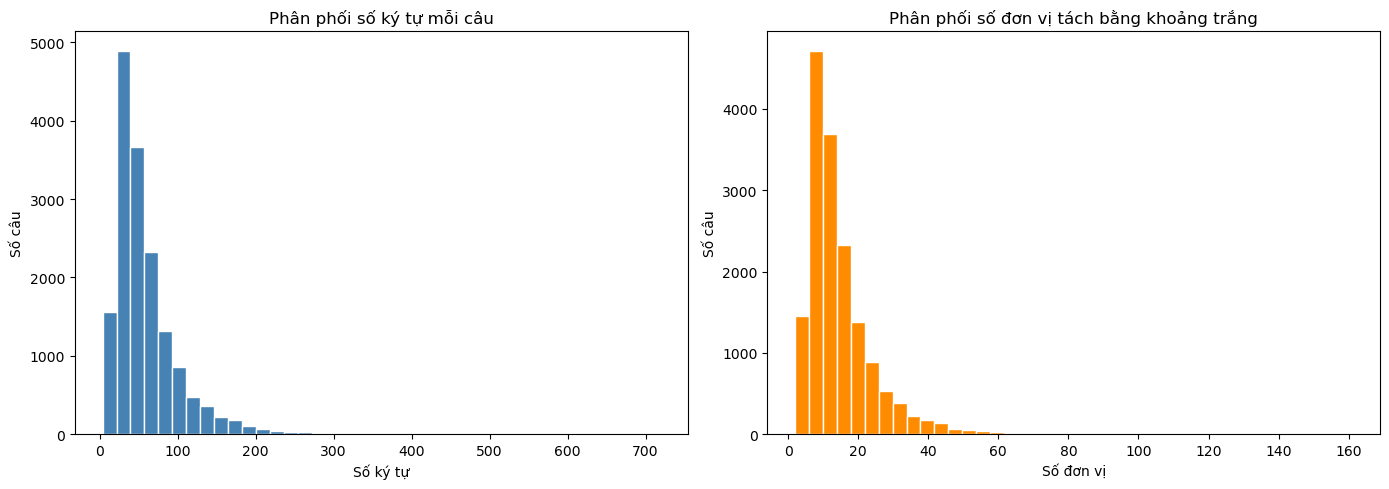

In [4]:
import matplotlib.pyplot as plt

text_df = all_df.copy()

# Số ký tự và số đơn vị cách nhau bằng khoảng trắng trong mỗi câu.
# Với tiếng Việt, số đơn vị này không hoàn toàn tương đương số từ.
text_df["char_count"] = text_df["sentence"].str.len()
text_df["whitespace_unit_count"] = text_df["sentence"].str.split().str.len()

print("Thống kê độ dài câu:")
display(
    text_df[["char_count", "whitespace_unit_count"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95])
    .round(1)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(text_df["char_count"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Phân phối số ký tự mỗi câu")
axes[0].set_xlabel("Số ký tự")
axes[0].set_ylabel("Số câu")

axes[1].hist(
    text_df["whitespace_unit_count"],
    bins=40,
    color="darkorange",
    edgecolor="white"
)
axes[1].set_title("Phân phối số đơn vị tách bằng khoảng trắng")
axes[1].set_xlabel("Số đơn vị")
axes[1].set_ylabel("Số câu")

plt.tight_layout()
plt.show()

Bivariate Analysis

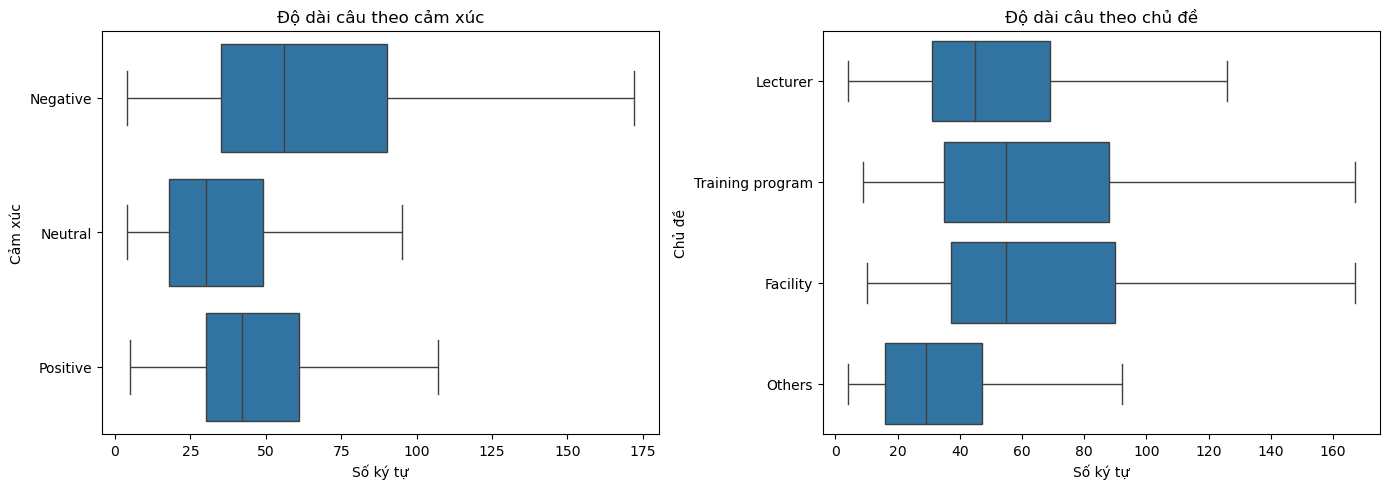

Độ dài câu theo cảm xúc:


,count,median,mean,max
sentiment_name,,,,
Negative,7439,56.0,70.5,718
Neutral,698,30.0,39.2,334
Positive,8038,42.0,49.6,394



Độ dài câu theo chủ đề:


,count,median,mean,max
topic_name,,,,
Lecturer,11607,45.0,56.6,718
Training program,3040,55.0,69.5,462
Facility,712,55.0,71.3,405
Others,816,29.0,39.2,334


In [5]:
import seaborn as sns

sentiment_order = ["Negative", "Neutral", "Positive"]
topic_order = ["Lecturer", "Training program", "Facility", "Others"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=text_df,
    x="char_count",
    y="sentiment_name",
    order=sentiment_order,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Độ dài câu theo cảm xúc")
axes[0].set_xlabel("Số ký tự")
axes[0].set_ylabel("Cảm xúc")

sns.boxplot(
    data=text_df,
    x="char_count",
    y="topic_name",
    order=topic_order,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Độ dài câu theo chủ đề")
axes[1].set_xlabel("Số ký tự")
axes[1].set_ylabel("Chủ đề")

plt.tight_layout()
plt.show()

print("Độ dài câu theo cảm xúc:")
display(
    text_df.groupby("sentiment_name")["char_count"]
    .agg(["count", "median", "mean", "max"])
    .reindex(sentiment_order)
    .round(1)
)

print("\nĐộ dài câu theo chủ đề:")
display(
    text_df.groupby("topic_name")["char_count"]
    .agg(["count", "median", "mean", "max"])
    .reindex(topic_order)
    .round(1)
)

Target Analysis

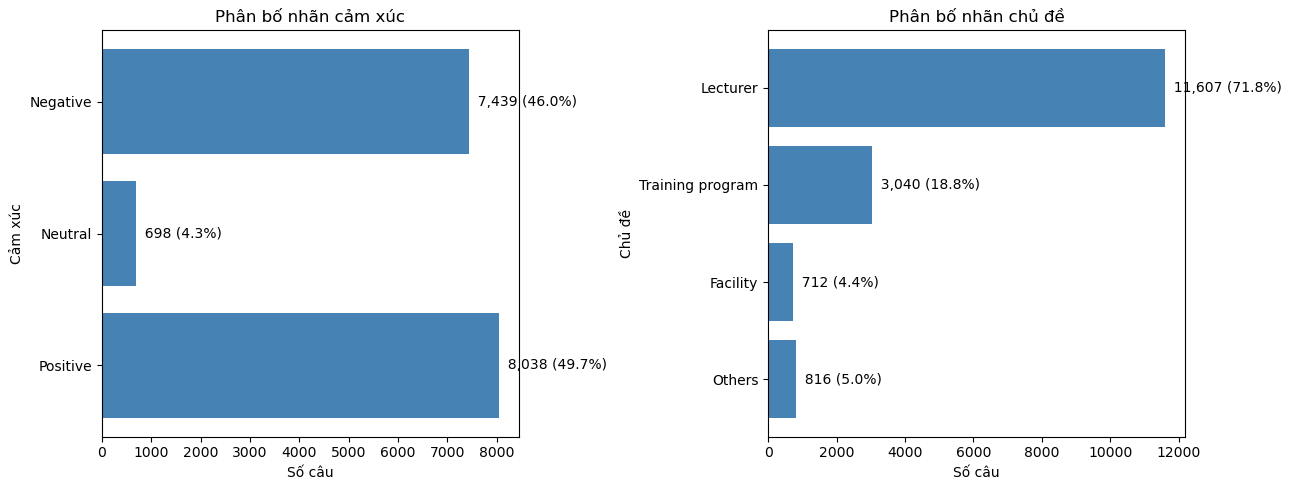

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

targets = [
    ("sentiment_name", sentiment_order, "Phân bố nhãn cảm xúc", "Cảm xúc"),
    ("topic_name", topic_order, "Phân bố nhãn chủ đề", "Chủ đề"),
]

for ax, (column, order, title, ylabel) in zip(axes, targets):
    counts = all_df[column].value_counts().reindex(order, fill_value=0)
    percentages = counts / counts.sum() * 100

    bars = ax.barh(counts.index, counts.values, color="steelblue")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Số câu")
    ax.set_ylabel(ylabel)

    for bar, count, percentage in zip(bars, counts.values, percentages.values):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"  {count:,} ({percentage:.1f}%)",
            va="center"
        )

plt.tight_layout()
plt.show()

Domain-specific EDA

Số câu theo chủ đề và cảm xúc:


sentiment_name,Negative,Neutral,Positive
topic_name,,,
Lecturer,4105,292,7210
Training program,2328,162,550
Facility,681,13,18
Others,325,231,260


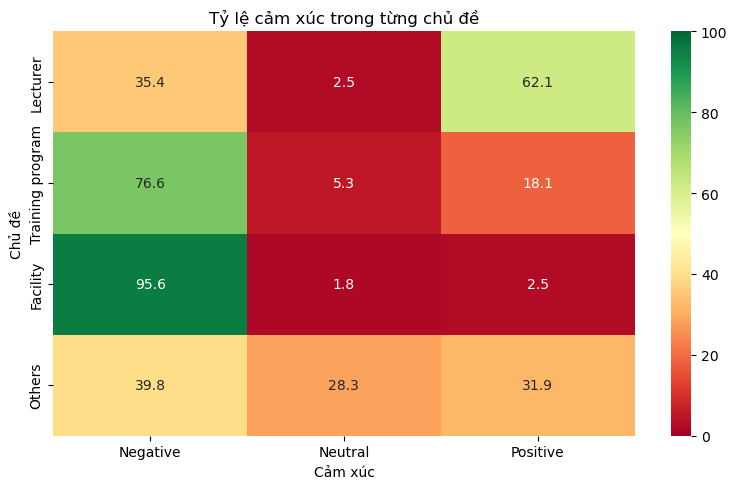

In [7]:
# Số câu của từng cặp chủ đề - cảm xúc
topic_sentiment_counts = pd.crosstab(
    all_df["topic_name"],
    all_df["sentiment_name"]
).reindex(index=topic_order, columns=sentiment_order, fill_value=0)

print("Số câu theo chủ đề và cảm xúc:")
display(topic_sentiment_counts)

# Tỷ lệ cảm xúc bên trong từng chủ đề
topic_sentiment_percent = (
    pd.crosstab(
        all_df["topic_name"],
        all_df["sentiment_name"],
        normalize="index"
    )
    .reindex(index=topic_order, columns=sentiment_order, fill_value=0)
    * 100
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    topic_sentiment_percent,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100
)
plt.title("Tỷ lệ cảm xúc trong từng chủ đề")
plt.xlabel("Cảm xúc")
plt.ylabel("Chủ đề")
plt.tight_layout()
plt.show()

EDA Conclusion

### Kết luận EDA

- Bộ dữ liệu UIT-VSFC có **16.175 câu phản hồi tiếng Việt**, gồm ba tập train, validation và test. Mỗi câu có hai nhãn: cảm xúc (`sentiment`) và chủ đề (`topic`).
- Không phát hiện giá trị thiếu hoặc câu rỗng. Có một câu xuất hiện hai lần trong tập train với cùng chủ đề nhưng mang nhãn cảm xúc trái ngược nhau (`Positive` và `Negative`). Đây là trường hợp nhãn không nhất quán cần lưu ý khi huấn luyện.
- Độ dài câu lệch phải: trung vị **46 ký tự**, trung bình **58,8 ký tự**; có một số câu dài đáng kể. Các câu Negative dài hơn về trung vị so với Positive và Neutral trong bộ dữ liệu này, nhưng độ dài câu không đủ để suy ra cảm xúc.
- Nhãn cảm xúc mất cân bằng: Positive chiếm **49,7%**, Negative **46,0%**, Neutral **4,3%**. Nhãn chủ đề mất cân bằng rõ hơn: Lecturer chiếm **71,8%**, Training program **18,8%**, Others **5,0%** và Facility **4,4%**.
- Phân bố cảm xúc khác nhau theo chủ đề trong dữ liệu: Lecturer chủ yếu Positive (**62,1%**); Training program chủ yếu Negative (**76,6%**); Facility có tỷ lệ Negative cao (**95,6%**); Others có phân bố cảm xúc cân bằng hơn. Đây là mối liên hệ quan sát được trong bộ dữ liệu, không thể diễn giải thành quan hệ nhân quả.
- Khi xây dựng mô hình, cần xác định rõ mục tiêu là dự đoán cảm xúc hay chủ đề. Nên giữ nguyên các split chính thức, xem precision/recall/F1 theo từng lớp và macro-F1 bên cạnh accuracy. Các lớp nhỏ, đặc biệt Neutral và một số chủ đề, cần được đánh giá cẩn thận.

**Lưu ý:** phân bố trong UIT-VSFC mô tả bộ dữ liệu này, không nhất thiết đại diện cho toàn bộ phản hồi sinh viên ngoài thực tế.